## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### Latest update: Jorge I. Zuluaga

## Testing Sorcha and Lyup

In [ ]:
import sorcha
import shutil
import layup
from util import *
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt

# Macros
DEG = np.pi / 180
RAD = 1 / DEG

ecl_coords, gal_coords = ecl_gal()

# Directories
!mkdir -p data figures
fig_dir='figures/'
data_dir='data/'
sorcha_dir='sorcha_data/'

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Get Survey Pointing Database

In [108]:
baseline_file = 'baseline_v2.0_1yr.db'
demo_db = os.path.dirname(sorcha.__file__) + '/data/demo/' + baseline_file
shutil.copy(demo_db, sorcha_dir + baseline_file)

'sorcha_data/baseline_v2.0_1yr.db'

### Get elements for a set of objects

In [24]:
# All fields in: https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html
fields = [
    'pdes', 
    'a', 'e', 'i', 'om', 'w', 'ma', 'epoch', 'H', 'G', 'spec_T'
    #'BV', 'UV', 'IR'
]
# Group and classes: https://ssd-api.jpl.nasa.gov/doc/sbdb_filter.html
params = {
    'fields': ','.join(fields),
    'sb-group': 'neo',
    'limit': '100'
}
url = 'https://ssd-api.jpl.nasa.gov/sbdb_query.api'
response = requests.get(url, params=params)
response.raise_for_status()
data = response.json()
df = pd.DataFrame(data['data'], columns=data['fields'])
df

,pdes,a,e,i,om,w,ma,epoch,H,G,spec_T
0,433,1.458,0.2229,10.83,304.27,178.92,62.51,2461200.5,10.40,0.46,S
1,719,2.637,0.5466,11.57,183.86,156.18,286.68,2461200.5,15.59,NaN,NaN
2,887,2.474,0.5711,9.40,110.41,350.55,132.18,2461200.5,13.82,-0.12,S
3,1036,2.664,0.5335,26.69,215.40,132.51,142.97,2461200.5,9.17,0.30,S
4,1221,1.92,0.4347,11.87,171.24,26.75,133.98,2461200.5,17.37,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
95,5626,2.195,0.4545,3.85,173.08,231.91,21.85,2461200.5,14.33,NaN,NaN
96,5645,1.355,0.3873,13.50,45.70,48.29,179.57,2461200.5,17.23,NaN,NaN
97,5646,2.144,0.4363,7.91,14.03,335.84,143.30,2461200.5,15.51,NaN,NaN
98,5653,1.794,0.3045,6.88,9.88,122.67,310.00,2461200.5,16.22,NaN,NaN


Adjust NaN values:

In [25]:
df['G'] = df['G'].fillna(0.15)
df['spec_T'] = df['spec_T'].fillna('C')
df

,pdes,a,e,i,om,w,ma,epoch,H,G,spec_T
0,433,1.458,0.2229,10.83,304.27,178.92,62.51,2461200.5,10.40,0.46,S
1,719,2.637,0.5466,11.57,183.86,156.18,286.68,2461200.5,15.59,0.15,C
2,887,2.474,0.5711,9.40,110.41,350.55,132.18,2461200.5,13.82,-0.12,S
3,1036,2.664,0.5335,26.69,215.40,132.51,142.97,2461200.5,9.17,0.30,S
4,1221,1.92,0.4347,11.87,171.24,26.75,133.98,2461200.5,17.37,0.15,C
...,...,...,...,...,...,...,...,...,...,...,...
95,5626,2.195,0.4545,3.85,173.08,231.91,21.85,2461200.5,14.33,0.15,C
96,5645,1.355,0.3873,13.50,45.70,48.29,179.57,2461200.5,17.23,0.15,C
97,5646,2.144,0.4363,7.91,14.03,335.84,143.30,2461200.5,15.51,0.15,C
98,5653,1.794,0.3045,6.88,9.88,122.67,310.00,2461200.5,16.22,0.15,C


### Catalogue generation

Orbit catalogue:

In [65]:
# 1. Generar catálogo orbital Kepleriano
df_orbits = pd.DataFrame({
    'ObjID': df['pdes'].astype(str),
    'a': df['a'].astype(float),
    'e': df['e'].astype(float),
    'inc': df['i'].astype(float),
    'node': df['om'].astype(float),
    'argPeri': df['w'].astype(float),
    'ma': df['ma'].astype(float),
    'epochMJD_TDB': df['epoch'].astype(float) - 2400000.5,
    'FORMAT': 'KEP'
})

orbits_cat = sorcha_dir + 'orbits.data'
df_orbits.to_csv(orbits_cat, sep='\t', index=False)

Color catalogue:

In [66]:
kurlander_colors = {
    'S-type': {
        'V-r': 0.35,
        'u-r': 1.62,
        'g-r': 0.78,
        'i-r': -0.50,  # -(r - i)
        'z-r': -0.71,  # -(r - z)
        'y-r': -0.92,  # -(r - y)
    },
    'C-type': {
        'V-r': 0.27,
        'u-r': 1.28,
        'g-r': 0.62,
        'i-r': -0.43,  # -(r - i)
        'z-r': -0.72,  # -(r - z)
        'y-r': -0.93,  # -(r - y)
    }
}

Create color catalogue:

In [67]:
df_colors = pd.DataFrame({'ObjID': df['pdes'].astype(str)})
for index in df.index:
    spec = df.loc[index]['spec_T']
    if spec == 'C':
        colors = kurlander_colors['C-type']
    else:
        colors = kurlander_colors['S-type']

    df_colors.loc[index,'GS'] = float(df.loc[index,'G'])
    df_colors.loc[index,'H_r'] = float(df.loc[index, 'H']) - colors['V-r']
    for key in colors.keys():
        if key == 'V-r':
            continue
        df_colors.loc[index,key] = colors[key]

colors_cat = sorcha_dir + 'colors.dat'
df_colors.to_csv(colors_cat, sep='\t', index=False)

In [68]:
# 3. Verificación con lectores nativos de Sorcha
from sorcha.readers.OrbitAuxReader import OrbitAuxReader
from sorcha.readers.CSVReader import CSVDataReader

orbits_test = OrbitAuxReader(orbits_cat, sep='whitespace').read_rows()
colors_test = CSVDataReader(colors_cat, sep='whitespace').read_rows()

Run Sorcha:

In [72]:
cmd = f"""sorcha run \
  -c {sorcha_dir + 'sorcha_config_demo.ini'} \
  -p {colors_cat} \
  --orbits {orbits_cat} \
  --pointing-db {sorcha_dir + 'baseline_v2.0_1yr.db'} \
  -o 'sorcha_data' \
  -t 'testrun' \
  --stats 'testrun_stats' \
  -f
"""
exit_code = os.system(cmd)

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


Extract objects:

In [77]:
df_obs = pd.read_csv(sorcha_dir + 'testrun.csv')
stats = pd.read_csv(sorcha_dir + 'testrun_stats.csv')

len(df_obs), len(df_obs['ObjID'].unique())

(2408, 49)

Map observations:

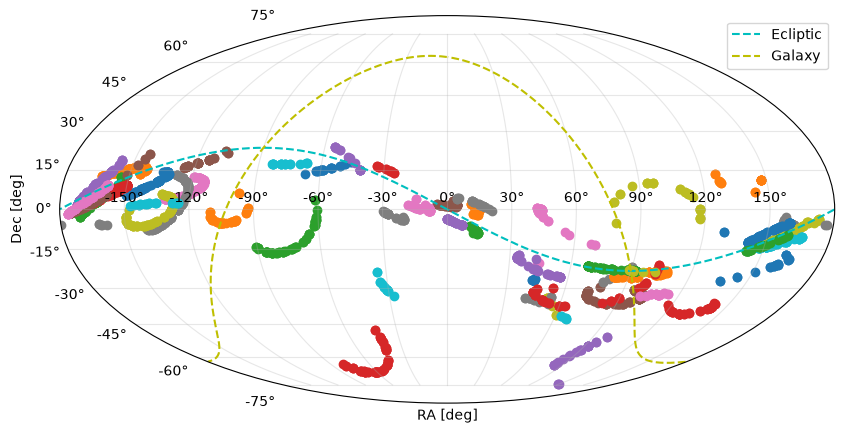

In [100]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='mollweide')

objs = df_obs['ObjID'].unique()
for i, obj in enumerate(objs):
    sub = df_obs[df_obs['ObjID'] == obj]
    ax.scatter(f2m(sub['RA_deg'])*DEG, sub['Dec_deg']*DEG)

ax.plot(*split_mollweide(ecl_coords[0], ecl_coords[1]), 'c--', label='Ecliptic')
ax.plot(*split_mollweide(gal_coords[0], gal_coords[1]), 'y--', label='Galaxy')
ax.legend()
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'sorcha-observations-map.png')


Extract light curve:

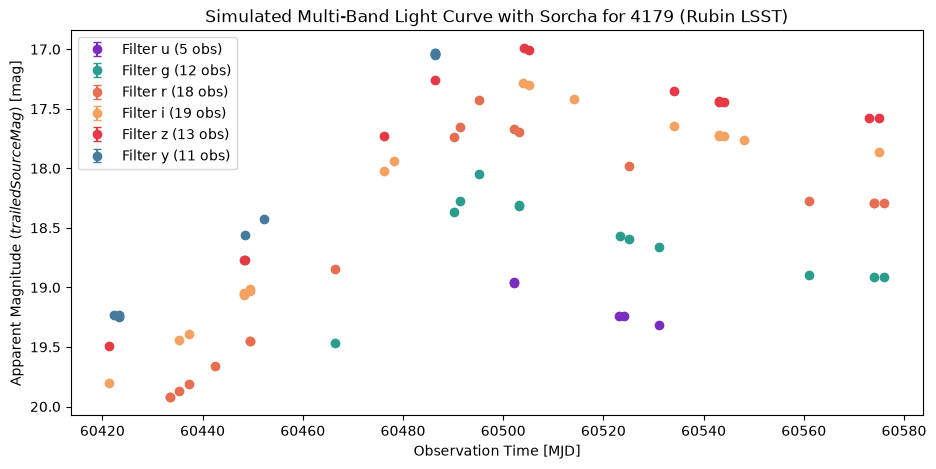

In [99]:
target_obj = 4179
df_target = df_obs[df_obs['ObjID'] == target_obj].sort_values('fieldMJD_TAI')

fig, ax = plt.subplots(figsize=(11, 5))
filter_palette = {
    'u': '#7b2cbf', 'g': '#2a9d8f', 'r': '#e76f51',
    'i': '#f4a261', 'z': '#e63946', 'y': '#457b9d'
}
for f in ['u', 'g', 'r', 'i', 'z', 'y']:
    sub_f = df_target[df_target['optFilter'] == f]
    if len(sub_f) > 0:
        ax.errorbar(sub_f['fieldMJD_TAI'], sub_f['trailedSourceMag'],
                    yerr=sub_f['trailedSourceMagSigma'], fmt='o',
                    color=filter_palette.get(f, 'black'),
                    label=f"Filter {f} ({len(sub_f)} obs)",
                    capsize=3, markersize=6)

ax.invert_yaxis()
ax.set_xlabel('Observation Time [MJD]')
ax.set_ylabel(r'Apparent Magnitude ($trailedSourceMag$) [mag]')
ax.set_title(f"Simulated Multi-Band Light Curve with Sorcha for {target_obj} (Rubin LSST)")
ax.legend(frameon=True)
plt.savefig(fig_dir + 'sorcha_lightcurve.png')